In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, roc_auc_score, confusion_matrix,
)
import joblib


log_reg = joblib.load("..\\003_Modeling\\log_reg.pkl")
X_test_clf = joblib.load("..\\003_Modeling\\X_test.pkl")
y_test_clf = joblib.load("..\\003_Modeling\\y_test.pkl")


In [7]:
target_names_clf = ["Low", "High"]

y_pred_log = log_reg.predict(X_test_clf)
y_prob_log = log_reg.predict_proba(X_test_clf)[:, 1]

accuracy_log = accuracy_score(y_test_clf, y_pred_log)
precision_log = precision_score(y_test_clf, y_pred_log, average="weighted")
recall_log = recall_score(y_test_clf, y_pred_log, average="weighted")
f1_log = f1_score(y_test_clf, y_pred_log, average="weighted")
roc_auc_log = roc_auc_score(y_test_clf, y_prob_log)

print(f"\n{'='*60}")
print(f"Logistic Regression (Pregnancy Risk Dataset)")
print(f"{'='*60}")
print(f"Accuracy:  {accuracy_log:.4f}")
print(f"Precision: {precision_log:.4f}")
print(f"Recall:    {recall_log:.4f}")
print(f"F1 Score:  {f1_log:.4f}")
print(f"ROC-AUC:   {roc_auc_log:.4f}")
print(f"\nClassification Report:")
print(classification_report(y_test_clf, y_pred_log, target_names=target_names_clf))


Logistic Regression (Pregnancy Risk Dataset)
Accuracy:  0.9701
Precision: 0.9703
Recall:    0.9701
F1 Score:  0.9700
ROC-AUC:   0.9974

Classification Report:
              precision    recall  f1-score   support

         Low       0.96      0.99      0.98       139
        High       0.98      0.95      0.96        95

    accuracy                           0.97       234
   macro avg       0.97      0.97      0.97       234
weighted avg       0.97      0.97      0.97       234



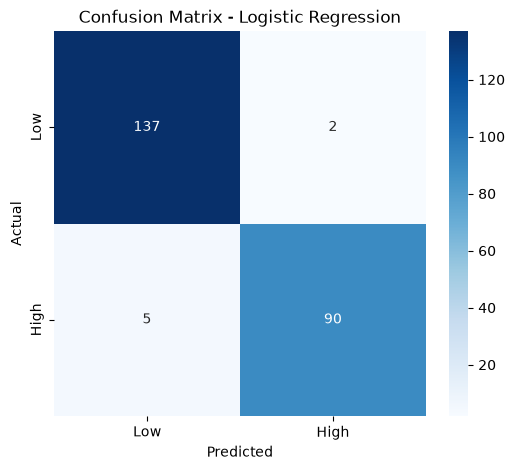

In [9]:
cm = confusion_matrix(y_test_clf, y_pred_log)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=target_names_clf,
    yticklabels=target_names_clf
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Logistic Regression")

plt.show()

The model performed well: out of 145 low-risk pregnancies, it correctly identified 137 and misclassified only 2.
Among 95 high-risk pregnancies, it correctly identified 90 and misclassified only 5 as low-risk.
In total, there were 7 incorrect predictions out of 240 samples.